# Introduction to Deep Learning, Assignment 2

## **Image to npz Converter**

In [ ]:
# Image to npz converter


import os
import numpy as np
from tqdm import tqdm
import random
from PIL import Image

DATA_DIR = "./images"     # folder containing images
N = 15000                 # number of images to select

def center_crop_square(img):
    """Center-crops a PIL image to a square."""
    w, h = img.size
    side = min(w, h)
    left = (w - side) // 2
    top = (h - side) // 2
    right = left + side
    bottom = top + side
    return img.crop((left, top, right, bottom))

# ---------------------------------------------------------
# 1) Gather image paths
# ---------------------------------------------------------
files = [
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

total = len(files)
print(f"Found {total} images in directory: {DATA_DIR}")

if total < N:
    raise ValueError(f"ERROR: dataset has only {total} images but N={N}")

# ---------------------------------------------------------
# 2) Shuffle and select
# ---------------------------------------------------------
random.shuffle(files)
selected_files = files[:N]
print(f"Randomly selected {len(selected_files)} images.\n")

# ---------------------------------------------------------
# 3) Prepare output array
# ---------------------------------------------------------
result = np.zeros((N, 96, 96, 3), dtype=np.uint8)

# ---------------------------------------------------------
# 4) Process images with progress output
# ---------------------------------------------------------
print("Processing images...\n")

for i, path in enumerate(selected_files):

    # Load
    img = Image.open(path).convert("RGB")

    # Crop ---> Resize ---> Array
    img = center_crop_square(img)
    img = img.resize((96, 96), Image.BICUBIC)
    arr = np.array(img, dtype=np.uint8)

    if arr.shape != (96, 96, 3):
        raise RuntimeError(f"Unexpected shape {arr.shape} for image: {path}")

    result[i] = arr

    # ---------- PROGRESS DISPLAY ----------
    if (i + 1) % 100 == 0 or i == 0:
        pct = (i + 1) * 100.0 / N
        bar_len = 30
        filled = int(bar_len * pct / 100)
        bar = "█" * filled + "-" * (bar_len - filled)
        print(f"[{bar}] {pct:5.1f}%  |  Processed {i+1}/{N}")
        print(f"   Current file: {os.path.basename(path)}")
    # --------------------------------------

# ---------------------------------------------------------
# 5) Save result
# ---------------------------------------------------------
out_path = "afde_22000_96x96.npz"
np.savez_compressed(out_path, images=result)   #  images=result means: the key stored inside the .npz is "images", so we will later extract it as   X = data["images"]


print("\nDONE!")
print("Saved to:", out_path)
print("Final shape:", result.shape)
print("dtype:", result.dtype)

### **Mount Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive') ## If you want to use your google drive

### If you are running on LIACS Lab machines, run the command below to reproduce the same package environment as Colab

#!pip install tf_keras==2.17.0 # Uncomment this to set up the right version

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Loading Libraries**

In [ ]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

from tqdm import tqdm
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model


# gpus = tf.config.list_physical_devices('GPU')
# for g in gpus:
#     tf.config.experimental.set_memory_growth(g, True)



### **Lading the Dataset**

As required, we use our customized dataset, called [AFDE](https://www.kaggle.com/datasets/ziggykor/anime-face-dataset-expanded-2024).  

Description:   
This dataset, consists of 135,027 Anime Faces (all jpgs in same size of 96x96).

We shuffle it, sample 22000 images from it, and then convert it to a 4D zipped numpy array (22000,96,96,3) of 22000 RGB 96x96 images: [`afde_22000_96x96.npz`](https://drive.google.com/file/d/19VscTT8k3m8k7YTM-nCutGy6FVztNJVq/view?usp=sharing) ~ 511 MB

Why this dataset?

- The anime faces has more color diversity than human faces. Thus it will display the interapolation better in VAE results . This also helps to see how model struggles in the first epochs to reconstruct images with plausible color channels.

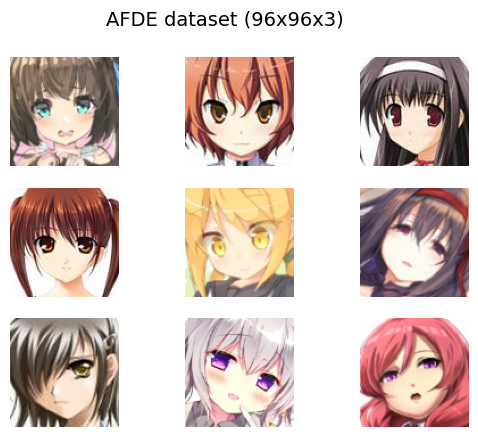

In [ ]:
# ============================================================
# IMAGE DIMENSIONS - Configure image size here
# ============================================================
image_height = 96
image_width = 96
# ============================================================

def load_real_samples(scale=False):
    N_images = 12000     # We may load a part of samples only, to avoid memory issues, you can change this value
    data = np.load('/content/drive/MyDrive/Colab Notebooks/afde_22000_96x96.npz')
    X = data["images"]                # <-- we extract the array
    X = X[:N_images, :, :, :]         # <-- then slice  a 4D numpy array: (N_images, 96, 96, 3)
    # if instead of npz we had npy:     X = np.load('/content/drive/MyDrive/Colab Notebooks/afde_22000_96x96.npz',  fix_imports=True,encoding='latin1')[:N_images, :, :, :]

    # Scales to [-1,1]  if  scale=True
    if scale:  # Map from [0,255] to [-1,1] (for tanh-based networks like GAN)
        X = (X - 127.5) * 2 / 255.0
        return X
    else:      # Map from [0,255] to [0,1] (suitable for sigmoid + BCE  in VAE and CAE)
        return X / 255.0

# We will use this function to display the output of our models throughout this notebook
def grid_plot(images, epoch='', name='', n=3, save=False, scale=False):
    if scale:
        images = (images + 1) / 2.0    # Scale from [-1,1] to [0,1] for plotting, because matplotlib expects [0,1]
    for index in range(n * n):         # n x n is the plotted grid size
        plt.subplot(n, n, 1 + index)   # Create subplot at index in a n x n grid
        plt.axis('off')
        plt.imshow(images[index])      # retrieves the image at index from ``images`` and plots it
    fig = plt.gcf()                                    # Get current figure
    fig.suptitle(name + '  '+ str(epoch), fontsize=14) # Add title to the current figure
    if save:
        filename = 'generated_plot_e%03d_f.png' % (epoch+1)
        plt.savefig(filename)
        plt.close()
    plt.show()


dataset = load_real_samples()    # it uses  `load_real_samples(scale=False)`  by default : the values are normalized into [0,1] range
grid_plot(dataset[np.random.randint(0, 1000, 9)], name='AFDE dataset (96x96x3)', n=3)  # Plot a random sample of 9 images from the dataset within the range 0-1000

## **Conv & deConv Nets**

In [ ]:
from tensorflow.keras.layers import Dense, Flatten, Conv2D, Conv2DTranspose, Reshape, Add, BatchNormalization


def residual_block(x, filters, kernel_size=3, scale=0.1):
    """Residual block with skip connection (preserves spatial dims). Scale controls residual strength."""
    shortcut = x
    x = Conv2D(filters, (kernel_size, kernel_size), padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = Conv2D(filters, (kernel_size, kernel_size), padding='same')(x)  # no activation before add
    x = BatchNormalization()(x)
    x = x * scale                                  # to scale down the residual branch
    x = Add()([shortcut, x])                       # `skip connection`
    x = tf.keras.activations.relu(x)
    return x


def build_conv_net(in_shape, out_shape, n_downsampling_layers=4, filters=128, out_activation='sigmoid', use_residual=False, kernel_size=3):  # "num of downsampling layers" = 1 + `n_downsampling_layers`
    """
    Build a basic convolutional encoder network

    Idea:
    - Taking an input image.
    - Repeatedly applying strided Conv2D layers for *downsampling* (reducing height/width, increasing abstraction).
    - Flattening the final feature maps.
    - Using a Dense layer at the *end* to compress all features into a latent vector of size `out_shape`.
        So this Dense layer is the final "bottleneck / encoder output".
    """
    # default args for all Conv2D layers:  stride=2 halves the spacial (W*H) size

    default_args=dict(kernel_size=(kernel_size, kernel_size), strides=(2,2), padding='same', activation='relu')

    # Input layer  --->  image tensor with `in_shape` (H, W, C).

    input = tf.keras.Input(shape=in_shape)                                                            #  input: 96, 96, 3

    # First conv layer (encoder input)  --->  Starting feature extraction and downsampling.
    # Each of 128 filters in Conv2D laye below:  mixes 3 channels & divides W nad H to `stride=2`

    x = Conv2D(filters=filters, name='enc_input', **default_args)(input)    # a single Conv2D outside/before the loop          #  96, 96, 3  --->  48, 48, 128
    if use_residual:
        x = residual_block(x, filters, kernel_size=kernel_size)

    # Repeating Downsampling layers  --->   e.g.: each layer outputs  `filters`=128  channels

    for _ in range(n_downsampling_layers):
        x = Conv2D(**default_args, filters=filters)(x)                                                #  48, 48, 128   --->   48/(2^4), 48/(2^4), 128  =  3, 3, 128
        if use_residual:
            x = residual_block(x, filters, kernel_size=kernel_size)

    # Flattening the final 3D feature map (H_final, W_final, filters) into a 1D vector of size  H_final * W_final * filters , gathers all spatial information into one vector.

    x = Flatten()(x)                                                                                  #   3, 3, 128  --->  3*3*128 = 1152,

    # encoder's ending Dense layer (connects all-to-all): high-dim flat vector ---> *latent vector* of size `out_shape`: bottleneck representation z
    x = Dense(out_shape, activation=out_activation, name='enc_output')(x)   # encoder's output as `out_shape`.

    model = tf.keras.Model(inputs=input, outputs=x, name='Encoder')    # Building the encoder model object with named input and output.

    model.summary()
    return model



def build_deconv_net(latent_dim, n_upsampling_layers=5, filters=128, activation_out='sigmoid', bottleneck_size=3, use_residual=False, kernel_size=3):  # "num of upsampling layers" = `n_upsampling_layers`
    """
    Build a deconvolutional network for decoding/upscaling latent vectors

    When building the deconvolutional architecture, usually it is best to use the same layer sizes that
    were used in the downsampling network and the Conv2DTranspose layers are used instead of Conv2D layers.
    Using identical layers and hyperparameters ensures that the dimensionality of our output matches the
    shape of our input images.

    Idea (mirror of encoder):
    - Taking a *latent vector* of size `latent_dim` as input.
    - First using a Dense layer at the *beginning* to expand this compact vector into a small spatial
        feature map (for example 4x4x64). This is the inverse of the encoder's final Dense+Flatten step.
    - Then using Conv2DTranspose layers (strided transposed convolutions) to
        *upsample* step by step until the spatial size matches the original image.
    - Finally using a 3-channel Conv2D layer to produce an RGB image with desired output activation.
    """
    input = tf.keras.Input(shape=(latent_dim,))                                             #  Inputs the latent vector z of shape (latent_dim,)

    # Dense layer at the *BEGINNING* of the decoder: as a learning layer between 2 [flat/1D] vectors, both of size 3*3*filters

    x = Dense(bottleneck_size * bottleneck_size * filters, input_dim=latent_dim, name='dec_input')(input)                #  `Input`:(latent_dim,)   --->   `x`:(bottleneck*bottleneck*filters,)

    # Reshaping vector to 3D tensor, but no Upscaling

    x = Reshape((bottleneck_size, bottleneck_size, filters))(x)                                                          #  (bottleneck*bottleneck*filters,)  --->  (bottleneck, bottleneck, filters)

    # Default args for Conv2DTranspose:  stride=2 Doubles the size

    default_args=dict(kernel_size=(kernel_size, kernel_size), strides=(2,2), padding='same', activation='relu')

    # Repeating upsampling layers --->  Each layer doubles H , W to gradually build higher-resolution

    for i in range(n_upsampling_layers):
        x = Conv2DTranspose(filters=filters, **default_args)(x)     # e.g. for n_up=5 , filters=128 :   (3,3,128) ---> (6,6,128) --->  ...  ---> (96,96,128) :  same as real observed images
        if use_residual:
            x = residual_block(x, filters, kernel_size=kernel_size)

    # Final Conv2D layer (not transposed):    multi-channel feature map  --->  back to a 3-channel RGB

    x = Conv2D(filters=3, kernel_size=(kernel_size, kernel_size), padding='same', activation=activation_out, name='dec_output')(x)    # e.g. Output layer :  (96,96,128) ---> (96,96,3)

    model = tf.keras.Model(inputs=input, outputs=x, name='Decoder')            # Building the decoder model object that maps  latent vector  to  reconstructed image.
    model.summary()
    return model



## **Task 1.1 - CAE**



In [ ]:
def build_convolutional_autoencoder(data_shape, latent_dim, filters=128, n_downsampling_layers=4, n_upsampling_layers=5, bottleneck_size=3, use_residual=False, kernel_size=3):
    encoder = build_conv_net(in_shape=data_shape, out_shape=latent_dim, n_downsampling_layers=n_downsampling_layers, filters=filters, use_residual=use_residual, kernel_size=kernel_size)
    decoder = build_deconv_net(latent_dim, activation_out='sigmoid', n_upsampling_layers=n_upsampling_layers, filters=filters, bottleneck_size=bottleneck_size, use_residual=use_residual, kernel_size=kernel_size)

    # We connect encoder and decoder into a single model
    autoencoder = tf.keras.Sequential([encoder, decoder])

    # BCE loss - pairwise comparison between   input pixels (loaded by `dataset = load_real_samples(scale=False)` : values in [0,1] range)   and   output pixels (sigmoid outputs: values in [0,1] range)
    autoencoder.compile(loss='binary_crossentropy', optimizer='adam')

    return autoencoder


# ============================================================
# CAE HYPERPARAMETERS - Configure all settings here
# ============================================================
latent_dim = 1024                                    # Latent space dimension (bottleneck size)
num_filters = 256                                   # Number of filters in conv layers (~ model capacity)
kernel_size = 3                                     # Convolutional kernel size (k x k)
n_downsampling_layers = 3                           # Number of downsampling layers in encoder (after first conv)   --->   `n_downsampling_layers` is actually  `n_downsampling_layers_in_conv2d_loops` (and we also have an single Conv2D layer outside/before the loop)
n_upsampling_layers = n_downsampling_layers + 1     # Total number of Conv2DTranspose layers in Decoder  =  Total number of Conv2D layers in Encoder
batch_size = 32
n_epochs = 100
use_residual = False                                # use residual blocks in encoder/decoder

# Computing bottleneck spatial size:  assume  image_height = image_width
bottleneck_size = image_height // (2 ** (1 + n_downsampling_layers))

# Validating bottleneck size constraints
if bottleneck_size < 2:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be >= 2. Reduce n_downsampling_layers.")
if bottleneck_size >= image_height:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be < image size ({image_height}). Increase n_downsampling_layers.")
# ============================================================

image_size = dataset.shape[1:]  # dataset.shape is (22000, 96, 96, 3)  --->  [1:] extracts (96, 96, 3): height, width, channels (96, 96, 3) - spatial dimensions of input images


# ------ MODEL LOADING: IF A SAVED ALREADY TRAINED MODEL EXISTS, THEN CONTINUE THE EPOCHS BY LOADING LEARNED WEIGHTS ----------
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/cae_model.keras"

if os.path.exists(MODEL_PATH):
    print(f"[INFO] Found saved model at: {MODEL_PATH}")
    cae = load_model(MODEL_PATH)
    print("[INFO] Loaded model successfully. Training will resume from saved weights.")
else:
    print(f"[WARNING] No saved model found at: {MODEL_PATH}")
    print("[INFO] Building a new model from scratch...")
    cae = build_convolutional_autoencoder(
        data_shape=image_size,
        latent_dim=latent_dim,
        filters=num_filters,
        n_downsampling_layers=n_downsampling_layers,
        n_upsampling_layers=n_upsampling_layers,
        bottleneck_size=bottleneck_size,
        use_residual=use_residual,
        kernel_size=kernel_size
    )
# ----------------------------------------------------------------


## Training the Convolutional autoencoder to reconstruct images
for epoch in range(n_epochs):
    print('\nEpoch: ', epoch)

    cae.fit(x=dataset, y=dataset, epochs=1, batch_size=batch_size)    # x=y when training autoencoders! : just testing th reconstruction ability/quality

    samples = dataset[:9]
    reconstructed = cae.predict(samples)                         # sampling and plotting 9 reconstructed images
    grid_plot(samples, epoch, name='Original', n=3, save=False)
    grid_plot(reconstructed, epoch, name='Reconstructed', n=3, save=False)

# Saving the trained model to Google Drive
cae.save('/content/drive/MyDrive/Colab Notebooks/cae_model.keras')

Output hidden; open in https://colab.research.google.com to view.

*Note: You may experiment with the latent dimensionality and number of filters in your convolutional network to see how it affects the reconstruction quality. Remember that this also affects the size of the model and time it takes to train.*

n_filters : howmany patterns each Conv2D layer extracts from the 2D feature map (~ model's complexity/capacity/flexibility)  

latent_dim : how much information of the tensor at the bottleneck (bottleneck_dim) is kept after flattening,


 **CAE 100 epochs**

## **Task 1.2 - VAE**

In [ ]:
###  Defining a customized type of network-layer by subclassing `tf.keras.layers.Layer` ###

class Sampling(tf.keras.layers.Layer):
    """
    Custom layer for the variational autoencoder
    It takes two vectors as input - one for means and other for variances of the latent variables
    that would be described by a multimodal gaussian as the posterior.
    Its output is a latent vector randomly sampled from this distribution
    (Takes μ and log σ² of q(z|x) and returns a stochastic latent sample z.)
    """
    # IMPLEMENTING THE `call` METHOD WHICH SPECIFIES WHAT HAPPENS WHEN THE LAYER PROCESSES `inputs` :
    def call(self, inputs):
        z_mean, z_var = inputs       #  z_mean= mu,  z_var=log(var)
        # e.g. 5 samples per mini-batch and  latent_dim=3 :  epsilon shape as (5, 3)  =>  one 3element noise vector per image (draws 15 scalars) -->  same shape for z_mean, z_var
        batch = tf.shape(z_mean)[0]  # number of samples (batch size) used to draw  epsilon ~ N(0,I)
        dim = tf.shape(z_mean)[1]    # dim of the latent space: size of latent vector z = number of latent variables
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))  # draw  epsilon ~ N(0,I)
        return z_mean + tf.exp(0.5 * z_var) * epsilon  # Reparameterization trick  z = mu + sigma.epsilon  with  sigma = exp(0.5 * z_var)



###  Defining the loss that works with continuous value in the compact range [0,1]
def continuous_bernoulli_loss(y_true, y_pred):
    """Continuous Bernoulli negative log-likelihood (proper loss for continuous [0,1] data)."""
    # Clamp predictions to avoid log(0)
    y_pred = tf.clip_by_value(y_pred, 1e-6, 1 - 1e-6)

    # Standard BCE terms
    bce = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)

    # Normalizing constant C(L) for continuous Bernoulli (L is lambda)
    lam = y_pred
    # Avoid numerical instability near L = 0.5
    unstable = tf.abs(lam - 0.5) < 1e-3

    # For stable regions: log C = log(2) + log(atanh(1-2L)) - log(|1-2L|)
    safe_lam = tf.where(unstable, 0.499 * tf.ones_like(lam), lam)
    log_C = tf.math.log(2.0) + tf.math.log(tf.abs(tf.math.atanh(1 - 2 * safe_lam)) + 1e-8) \
            - tf.math.log(tf.abs(1 - 2 * safe_lam) + 1e-8)

    # Near L = 0.5,  log C is nearly log(2)
    log_C = tf.where(unstable, tf.math.log(2.0) * tf.ones_like(log_C), log_C)

    # CB NLL = BCE - log C (subtract because C normalizes the density)
    return bce - log_C

In [ ]:

def build_vae(data_shape, latent_dim=128, filters=256, beta=0.9, learning_rate=6e-4, beta_1=0.9, n_downsampling_layers=4, n_upsampling_layers=5, bottleneck_size=3, use_residual=False, kernel_size=3):      # `beta` is weighting the KL-loss w.r.t. reconstruction loss in total loss :  beta-VAE

    """
    Encoder - intro
    """
    # Encoder q(z|x) :  first part maps input x (in_shape = data_shape) to a concatenatenation of 2 vectors that are going to give mu and log(var)  =>  out_shape = latent_dim*2 . Then the second part uses 2 dense heads to output mu and log(var) separately.
    """
    Encoder Part 1  -->  returns a model:  tf.keras.Model(..., outputs=x, ...)  , where   x = Dense(out_shape, ...)   is  a vector of size  out_shape.
    """
    encoder_base = build_conv_net(in_shape=data_shape,
                                  out_shape=latent_dim * 2,    # default:  out_activation='sigmoid'
                                  n_downsampling_layers=n_downsampling_layers,
                                  filters=filters,
                                  use_residual=use_residual,
                                  kernel_size=kernel_size)   # default:  filters=128
    # tf.keras.Model()  is a class whose output can be retrieved by the  `.output`  attribute, which gives us the output tensor →  here, a vector whose shape is  out_shape=(latent_dim*2,)

    """
    Encoder Part 2   -->   Input shape (the output shape of Encoder Part 1) : (latent_dim*2,)  ,    Output shape: (latent_dim,)  :  this is  z_mean (HEAD1)  or  z_var (HEAD2)  below
    """
    # Note: multiple images of a (mini-)batch are fed to the encoder at once, so the actual input shape above is (batch_size, latent_dim*2)  and output shape is (batch_size, latent_dim)

    ### Adding special sampling layer that uses the reparametrization trick :   Linear heads split q(z|x) into mu(x) and log(var(x))

    z_mean_raw = Dense(latent_dim)(encoder_base.output)   # OUTPUT HEAD 1       activation(weight @ input + bias)  -->    weight shape: (latent_dim*2, latent_dim)   ,   bias shape: (latent_dim,)
    z_var_raw  = Dense(latent_dim)(encoder_base.output)   # OUTPUT HEAD 2       each weight & bias in these two heads, are randomly initialized separately & also learned independently.
    #
    # z_mean: Dense layer has no activation function (default is linear) ---> outputs unbounded values in (-inf,+inf).
    # z_var : log(var)  --->  values in (-inf,+inf)

    class KLLossLayer(tf.keras.layers.Layer):     # custom layer for the KL loss: computes KL divergence term D_KL(q(z|x) || p(z))

        def call(self, inputs):

            z_mean, z_var = inputs                                                             # diagonal Gaussian
            # KL divergence per latent dimension: mean over latent_dim and batch
            # This gives ~0.5-1.0 per latent dimension (similar scale to per-pixel recon loss)
            kl_per_sample = -0.5 * tf.reduce_mean( 1 + z_var - tf.square(z_mean) - tf.exp(z_var), axis=1 )  # shape: (batch_size,) - MEAN over latent
            kl_loss = tf.reduce_mean(kl_per_sample)                                            # averages over batch
            self.add_loss(beta * kl_loss)
            return z_mean, z_var

    # SAMPLING & COMBINING THE TWO HEADS:   takes list of 2 tensors, each of shape (batch_size, latent_dim) : [z_mean, z_var]  -->  gives a Stochastic latent tensor of shape (batch_size, latent_dim) , sampled as  z = z_mean + exp(z_var) . epsilon
    z_mean, z_var = KLLossLayer()([z_mean_raw, z_var_raw])
    z = Sampling()([z_mean, z_var])                         # sampling_layer = Sampling()   ,   z = sampling_layer([z_mean, z_var])

    """
    Encoder (Total)
    """
    encoder = tf.keras.Model(inputs=encoder_base.input, outputs=z)   # Connecting the two encoder parts: Defines encoder model returning latent sample z

    """
    Decoder      p(x|z): transposed-conv net approximating likelihood of input data   (a regular upsampling deconvolutional network)
    """
    decoder = build_deconv_net(latent_dim,
                               activation_out='sigmoid',
                               n_upsampling_layers=n_upsampling_layers,
                               filters=filters,
                               bottleneck_size=bottleneck_size,
                               use_residual=use_residual,
                               kernel_size=kernel_size)

    """
    Total VAE (Encoder + Decoder + KL Loss)
    """
    vae = tf.keras.Model(inputs=encoder.input, outputs=decoder(z))   # Composing encoder and decoder: x* = decoder(z) with z sampled from q(z|x)

    # `Total Loss`  =  `Reconstruction Loss (binary crossentropy)`  +  beta * `[normalized] KL Loss`

    """
    Compile VAE Model
    """

    vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, beta_1=beta_1),   # Reconstruction loss: Continuous Bernoulli NLL (proper for continuous [0,1] pixel values)
                loss=continuous_bernoulli_loss)

    return encoder, decoder, vae


# in VAE the loss compares input and output (both should have same size H*W*C) in a pixel-wise way. This pixel-wise comparison also implies a channel-wise comparison, so each pixel of a
# channel (C1,C2,C3) in the output is compared to the corresponding color channel (R,G,B) in the input. Hence, the network learns to construct C1 to match R,  C2 to match G,  and C3 to match B.

In [ ]:
# Training the VAE model

# ============================================================
# VAE HYPERPARAMETERS - Configure all settings here
# ============================================================
latent_dim = 1024
num_filters = 256
kernel_size = 3               # Convolutional kernel size (k x k)
beta = 0.3                    # KL loss weight (normalized): beta=1 means equal weight to reconstruction
learning_rate = 2e-4           # Adam optimizer learning rate
beta_1 = 0.5                   # Adam optimizer momentum
n_downsampling_layers = 4
n_upsampling_layers = n_downsampling_layers + 1   # considering the lonely downsampling layer
batch_size = 32
n_epochs = 20
coefficient = 0.9            # Latent vector scaling for generation (smaller = more diverse)
use_residual = False           # use residual blocks in encoder/decoder

# Computing bottleneck spatial size: image_size / 2^(1 + n_downsampling_layers)
bottleneck_size = image_height // (2 ** (1 + n_downsampling_layers))

# Validating bottleneck size constraints
if bottleneck_size < 2:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be >= 2. Reduce n_downsampling_layers.")
if bottleneck_size >= image_height:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be < image size ({image_height}). Increase n_downsampling_layers.")
# ============================================================

encoder, decoder, vae = build_vae(
    data_shape=dataset.shape[1:],
    latent_dim=latent_dim,
    filters=num_filters,
    beta=beta,
    learning_rate=learning_rate,
    beta_1=beta_1,
    n_downsampling_layers=n_downsampling_layers,
    n_upsampling_layers=n_upsampling_layers,
    bottleneck_size=bottleneck_size,
    use_residual=use_residual,
    kernel_size=kernel_size
)

WEIGHTS_PATH = "/content/drive/MyDrive/Colab Notebooks/vae.weights.h5"

# ----------------------------------------------------------------------
# loads previous VAE weights if available
# ----------------------------------------------------------------------
if os.path.exists(WEIGHTS_PATH):
    print(f"[INFO] Found saved VAE weights at: {WEIGHTS_PATH}")
    vae.load_weights(WEIGHTS_PATH)
    print("[INFO] Loaded pretrained weights. Continuing training.")
else:
    print("[INFO] No saved VAE weights found. Starting from scratch.")
# ----------------------------------------------------------------------

# Training loop
for epoch in range(n_epochs):
    vae.fit(x=dataset, y=dataset, epochs=1, batch_size=batch_size)    #  Setting batch size does not affects the intrapolation since we normalized KL loss by 1/B.

    # Larger batch_size : Gradient calculations and weight updates are based on more samples -->  more accurate (stable estimate, less oscillations, faster convergence) but lesser noise (increases stucking in shallow local minima) and blurry images rather than sharp/fragmented.

    latent_vectors = np.random.randn(9, latent_dim)                   # 3x3 = 9  points  randomly drawn  from latent space
    images = decoder(latent_vectors / coefficient)                    # Feed the vectors scaled by the coefficient to the model
    grid_plot(images, epoch, name='VAE generated images (randomly sampled from the latent space)', n=3, save=False)

# ----------------------------------------------------------------------
# Saving updated weights for next run (after the training loop finishes)
# ----------------------------------------------------------------------
vae.save_weights(WEIGHTS_PATH)
print(f"[INFO] Saved updated VAE weights to: {WEIGHTS_PATH}")

Output hidden; open in https://colab.research.google.com to view.

Euclidean distance between z1 and z2: 44.7160


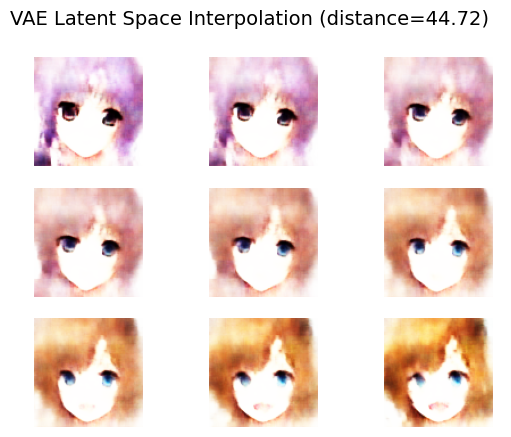

In [ ]:
# ============================================================
# VAE Latent Space Interpolation
# ============================================================
# Generates two random latent vectors
z1 = np.random.randn(1, latent_dim)
z2 = np.random.randn(1, latent_dim)

# Calculates distance and create 9 evenly spaced vectors (including endpoints)
n_interpolations = 9
alphas = np.linspace(0, 1, n_interpolations)  # [0, 0.125, 0.25, ..., 1]

# Linear interpolation: z = (1 - alpha) * z1 + alpha * z2
interpolated_vectors = np.array([(1 - alpha) * z1 + alpha * z2 for alpha in alphas])
interpolated_vectors = interpolated_vectors.reshape(n_interpolations, latent_dim)

# Generates images from interpolated latent vectors
interpolated_images = decoder(interpolated_vectors)

# Calculates and display the distance between the two endpoints
distance = np.linalg.norm(z2 - z1)
print(f"Euclidean distance between z1 and z2: {distance:.4f}")

# Plots the interpolation
grid_plot(interpolated_images.numpy(), name=f'VAE Latent Space Interpolation (distance={distance:.2f})', n=3, save=False)


larger num of filters --> more capacity to capture richer details --> sharper images generated


coefficient smaller than 1 --> higher within epoch variations --> more diversity in images generated --> sharper colors


smaller KL-weight beta --> less globally coherent images --> less globally meaningful --> but more local patterns -->  sharper images


larger latent_dim  -->  more model capacity at bottleneck  --> sharper (but maybe noisy) images

**VAE (with CBL) ~350 epochs by re-executing on the saved weights**

In [ ]:
# Note: Latent Dimension and Number of Filters are two independent parameters: e.g.


# Input Image (96×96×3)
#     ↓
# ┌────────────────────────────────────────────┐
# │  ENCODER CONVOLUTIONAL PART                │
# │  Uses: filters = 256                       │
# │  Independent of latent_dim!                │
# ├────────────────────────────────────────────┤
# │  Conv2D(filters=256): 96×96×3 → 48×48×256  │
# │  Conv2D(filters=256): 48×48×256 → 24×24×256│
# │  Conv2D(filters=256): 24×24×256 → 12×12×256│
# │  Conv2D(filters=256): 12×12×256 → 6×6×256  │
# │  Conv2D(filters=256): 6×6×256 → 3×3×256    │
# │  Flatten: 3×3×256 → 2,304                  │
# └────────────────────────────────────────────┘
#     ↓
# ┌────────────────────────────────────────────┐
# │  ENCODER DENSE PART                        │
# │  Uses: latent_dim = 512                    │
# │  This is where they connect!               │
# ├────────────────────────────────────────────┤
# │  Dense(latent_dim*2): 2,304 → 1,024        │ ← out_shape = latent_dim*2
# │  Dense(latent_dim): 1,024 → 512 (z_mean)   │
# │  Dense(latent_dim): 1,024 → 512 (z_var)    │
# │  Sampling: (z_mean, z_var) → z (512)       │
# └────────────────────────────────────────────┘
#     ↓
# ┌────────────────────────────────────────────┐
# │  DECODER DENSE PART                        │
# │  Uses BOTH: latent_dim AND filters         │
# ├────────────────────────────────────────────┤
# │  Dense(3×3×filters): 512 → 2,304           │ ← Both params used here!
# │  Reshape: 2,304 → 3×3×256                  │
# └────────────────────────────────────────────┘
#     ↓
# ┌──────────────────────────────────────────────┐
# │  DECODER CONVOLUTIONAL PART                  │
# │  Uses: filters = 256                         │
# │  Independent of latent_dim!                  │
# ├──────────────────────────────────────────────┤
# │  Conv2DTranspose(256): 3×3×256 → 6×6×256     │
# │  Conv2DTranspose(256): 6×6×256 → 12×12×256   │
# │  Conv2DTranspose(256): 12×12×256 → 24×24×256 │
# │  Conv2DTranspose(256): 24×24×256 → 48×48×256 │
# │  Conv2DTranspose(256): 48×48×256 → 96×96×256 │
# │  Conv2D(3): 96×96×256 → 96×96×3              │
# └──────────────────────────────────────────────┘
#     ↓

# Output Image (96×96×3)

---
---
---
---
---
---
---

## **Task 1.3 - GAN**

In [ ]:
# The adversarial game:

from tensorflow.keras.optimizers.legacy import Adam


def build_gan(data_shape, latent_dim, filters=256, lr=2e-4, beta_1=0.5, n_downsampling_layers=4, n_upsampling_layers=5, bottleneck_size=3, use_residual=False, kernel_size=3):      # lr: learning rate  ,  beta_1: momentum

    opt_d = Adam(learning_rate=lr, beta_1=beta_1)   # optimizer for discriminator
    opt_g = Adam(learning_rate=lr, beta_1=beta_1)   # optimizer for GAN / generator


    # maps:   noise vector (latent_dim,)  -->  image (96, 96, 3)
    generator = build_deconv_net(latent_dim,
                                 n_upsampling_layers=n_upsampling_layers,
                                 filters=filters,
                                 activation_out='tanh',
                                 bottleneck_size=bottleneck_size,
                                 use_residual=use_residual,
                                 kernel_size=kernel_size)              # tanh outputs in [-1, 1]

    # maps    image (96, 96, 3)  -->  probability scalar (1,)
    discriminator = build_conv_net(in_shape=data_shape,
                                   out_shape=1,
                                   n_downsampling_layers=n_downsampling_layers,
                                   filters=filters,
                                   out_activation='sigmoid',
                                   use_residual=use_residual,
                                   kernel_size=kernel_size)            # single output neuron (real=1, fake=0)


    discriminator.compile(loss='binary_crossentropy', optimizer=opt_d)     # BCE loss is for Pr(real) classification labels, not for pixels values

    discriminator.trainable = False    # Freeze discriminator weights  for/when  training the generator

    # Connecting generator output to discriminator to create end-to-end GAN   :   Passes generator's fake images through (frozen) discriminator

    true_fake_prediction = discriminator(generator.output)      # computation graph:     noise z  -->  generator fools  -->  fake_images_batch: (batch_size, 96, 96, 3)  -->  discriminator catches  -->  prediction: Pr(real)

    GAN = tf.keras.Model(inputs=generator.input, outputs=true_fake_prediction)

    # to update generator weights (training) while discriminator's parameters are kept frozen:
    #   - Loss function      : defines how to measure error
    #   - Optimizer (Adam)   : defines how to update weights to minimize loss
    #   - Metrics (optional) : tracks performance during training
    GAN.compile(loss='binary_crossentropy', optimizer=opt_g)

    return discriminator, generator, GAN  # all three models

### Definining custom functions for training your GANs

---




In [ ]:
# latent_dim is NOT an encoder dimension (as in VAE), but is only the dimension of the noise input to the Generator.


def get_batch(generator, dataset, latent_dim, batch_size=64):
    """
    Fetches one batch of data and helps avoiding unnecessary overhead by using TensorFlow operations.
    """
    half_batch = batch_size // 2

    # Generates fake images
    latent_vectors = tf.random.normal(shape=(half_batch, latent_dim))
    fake_data = generator(latent_vectors, training=False)

    # Selects real images
    idx = np.random.randint(0, dataset.shape[0], half_batch)
    real_data = dataset[idx]

    # Combines
    X = tf.concat([real_data, fake_data], axis=0)
    y = tf.concat([tf.ones((half_batch, 1)), tf.zeros((half_batch, 1))], axis=0)

    return X, y




def train_gan(generator, discriminator, gan, dataset, latent_dim, n_epochs=20, batch_size=64):
    """
    Train the GAN with memory-efficient updates.
    """
    batches_per_epoch = dataset.shape[0] // batch_size

    for epoch in range(n_epochs):
        for batch in tqdm(range(batches_per_epoch)):

            # Training Discriminator via its own compiled model: Gets a batch with half real images (labeled 1) and half fake images (labeled 0), and tries to distinguish real from fake
            X, y = get_batch(generator, dataset, latent_dim, batch_size)
            discriminator_loss = discriminator.train_on_batch(X, y)

            # Training Generator by the GAN model (with discriminator frozen). Target is all 1s (telling the generator that `your goal is to make discriminator think fakes are real`)
            latent_vectors = tf.random.normal(shape=(batch_size, latent_dim))
            y_gan = tf.ones((batch_size, 1))  # Labels are all set to 1
            generator_loss = gan.train_on_batch(latent_vectors, y_gan)
            #
            # During Generator Training:
            #  1- Generator creates fake images from random noise
            #  2- Frozen discriminator evaluates them → outputs probabilities (e.g., 0.2 = "looks fake")
            #  3- Binary crossentropy loss is computed between:  Discriminator's prediction (e.g., 0.2)   and   Our target label (1.0 = "we want discriminator to think it's real")
            #  4- Loss is high (because 0.2 is far from 1.0)
            #  5- Gradients flow backward through the frozen discriminator to the generator (carrying the info of that Loss from the discriminator to the generator)
            #  6- Only generator weights are updated to produce more realistic images

        # We generate and visualize after each epoch
        noise = tf.random.normal(shape=(16, latent_dim))
        generated_images = generator(noise, training=False)
        # generator outputs are in [-1,1] (tanh), so we pass scale=True to map them to [0,1] for plotting
        grid_plot(generated_images.numpy(), epoch, name='Generated Images', n=3, scale=True)


In [ ]:
## Build and train the model (need around 10–20 epochs to start seeing some results)

# ============================================================
# GAN HYPERPARAMETERS - Configure all settings here
# ============================================================
latent_dim = 256              # Latent space dimension (noise vector size for generator)
num_filters = 256             # Number of filters in conv layers (model capacity)
kernel_size = 3               # Convolutional kernel size (k x k)
learning_rate = 2e-4          # Adam optimizer learning rate
beta_1 = 0.5                  # Adam optimizer momentum
n_downsampling_layers = 4     # Number of downsampling layers in discriminator (after first conv)
n_upsampling_layers = n_downsampling_layers + 1  # Generator upsampling layers (must be +1 to match output size)
batch_size = 64               # Training batch size
n_epochs = 50                 # Number of training epochs
use_residual = False          # use residual blocks in generator/discriminator

# Computing bottleneck spatial size: image_size / 2^(1 + n_downsampling_layers)
bottleneck_size = image_height // (2 ** (1 + n_downsampling_layers))

# Validating bottleneck size constraints
if bottleneck_size < 2:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be >= 2. Reduce n_downsampling_layers.")
if bottleneck_size >= image_height:
    raise ValueError(f"Bottleneck size ({bottleneck_size}) must be < image size ({image_height}). Increase n_downsampling_layers.")
# ============================================================

# Building GAN components (discriminator, generator, GAN)
discriminator, generator, gan = build_gan(
    data_shape=dataset.shape[1:],
    latent_dim=latent_dim,
    filters=num_filters,
    lr=learning_rate,
    beta_1=beta_1,
    n_downsampling_layers=n_downsampling_layers,
    n_upsampling_layers=n_upsampling_layers,
    bottleneck_size=bottleneck_size,
    use_residual=use_residual,
    kernel_size=kernel_size
)

dataset_scaled = load_real_samples(scale=True)  # we rescale images from [0,1] t [-1,1] so that the input range is consistent with the tanh output range

# in  VAE, the BCE loss is for  " sigmoid outputs:  pixel values as  0 <  Pr(`pixel is on')   < 1 "
# but GAN uses BCE loss for the " sigmoid outputs:  image labels as  0 <  Pr(`image is real`) < 1 "  ,  while pixel values are in range [-1,1] (tanh outputs)

GAN_WEIGHTS_PATH = "/content/drive/MyDrive/Colab Notebooks/gan.weights.h5"

# --------------------------------------------
# loads previous GAN weights if available
# --------------------------------------------
if os.path.exists(GAN_WEIGHTS_PATH):
    print(f"[INFO] Found saved GAN weights at: {GAN_WEIGHTS_PATH}")
    gan.load_weights(GAN_WEIGHTS_PATH)
    print("[INFO] Loaded pretrained weights. Continuing training.")
else:
    print("[INFO] No saved GAN weights found. Starting from scratch.")
# --------------------------------------------

# Training the GAN on the scaled dataset
train_gan(generator, discriminator, gan,
          dataset_scaled, latent_dim, n_epochs=n_epochs, batch_size=batch_size)

# --------------------------------------------
# Saving updated GAN weights for next run
# --------------------------------------------
gan.save_weights(GAN_WEIGHTS_PATH)
print(f"[INFO] Saved updated GAN weights to: {GAN_WEIGHTS_PATH}")

Output hidden; open in https://colab.research.google.com to view.

*Note: the samples generated by small GANs are more diverse, when compared to VAEs, however some samples might look strange and do not resemble the data the model was trained on.

Euclidean distance between z1 and z2: 21.3736


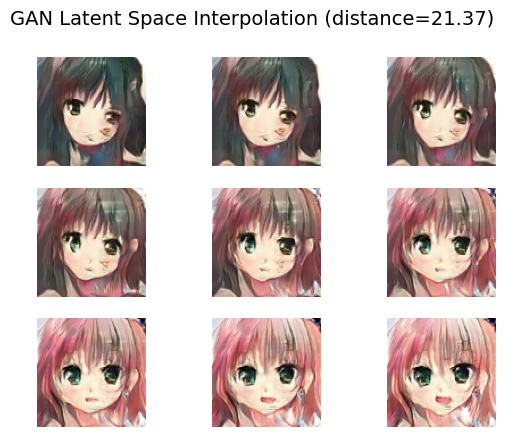

In [ ]:
# ============================================================
# GAN Latent Space Interpolation
# ============================================================
# Generates two random latent vectors
z1 = np.random.randn(1, latent_dim)
z2 = np.random.randn(1, latent_dim)

# Calculates distance and create 9 evenly spaced vectors (including endpoints)
n_interpolations = 9
alphas = np.linspace(0, 1, n_interpolations)  # [0, 0.125, 0.25, ..., 1]

# Linear interpolation: z = (1 - alpha) * z1 + alpha * z2
interpolated_vectors = np.array([(1 - alpha) * z1 + alpha * z2 for alpha in alphas])
interpolated_vectors = interpolated_vectors.reshape(n_interpolations, latent_dim)

# Generates images from interpolated latent vectors
interpolated_images = generator(interpolated_vectors, training=False)

# Calculates and displays the distance between the two endpoints
distance = np.linalg.norm(z2 - z1)
print(f"Euclidean distance between z1 and z2: {distance:.4f}")

# Plots the interpolation (scale=True because GAN outputs are in [-1,1])
grid_plot(interpolated_images.numpy(), name=f'GAN Latent Space Interpolation (distance={distance:.2f})', n=3, scale=True, save=False)

GAN 100~120 epochs using saved weights